In [2]:
import numpy as np
import matplotlib.pyplot as plt
from filterpy.kalman import KalmanFilter
from pathlib import Path
import pickle
import yaml

In [3]:
from setup import (
    colors,
    plot_style,
    filepath,
    configuration,
    training_labels,
    spectral_range,
    rise_time,
    training_settling_time as settling_time,
    calibration_type,
    predictor_type,
)
from processing import (
    is_system_settled,
    scaling_from_pid_to_cell,
)

In [4]:
plt.style.use(plot_style)

### Load training datasets

In [5]:
times = []
voltages = []
spectral_predictors = []
flowrates = []
setpoints = []
are_settled = []
are_analyte_free = []

wavenumber = None
spectral_resolution = None
gas_1 = None
gas_2 = None
split_ratio = None
window_type = None
correction_type = None
signal_type = None

for label in training_labels:
    dataset = np.load(filepath / f"{label}.npz")
    metadata = yaml.safe_load((filepath / f"{label}.yaml").read_text())

    if spectral_resolution is None:
        spectral_resolution = metadata["sampling"]["spectral_resolution"]
    elif spectral_resolution != metadata["sampling"]["spectral_resolution"]:
        raise ValueError(f"Spectral resolution mismatch for {label}.")

    time = dataset["time"]
    spectrum = dataset["spectrum"]

    if wavenumber is None:
        wavenumber = dataset["wavenumber"]
        spectral_mask = (wavenumber >= spectral_range[0]) & (
            wavenumber <= spectral_range[1]
        )
    elif wavenumber.shape != dataset["wavenumber"].shape:
        raise ValueError(f"Wavenumber mismatch for {label}.")
    elif not np.allclose(wavenumber, dataset["wavenumber"], atol=1e-3):
        raise ValueError(f"Wavenumber mismatch for {label}.")

    if gas_1 is None:
        gas_1 = str(dataset["gas_1"])
    elif gas_1 != str(dataset["gas_1"]):
        raise ValueError(f"Gas 1 mismatch for {label}.")

    if gas_2 is None:
        gas_2 = str(dataset["gas_2"])
    elif gas_2 != str(dataset["gas_2"]):
        raise ValueError(f"Gas 2 mismatch for {label}.")

    if split_ratio is None:
        split_ratio = float(dataset["split_ratio"])
    elif split_ratio != float(dataset["split_ratio"]):
        raise ValueError(f"Split ratio mismatch for {label}.")

    if dataset["type"] == "twins":
        if window_type is None:
            window_type = str(dataset["window_type"])
        elif window_type != str(dataset["window_type"]):
            raise ValueError(f"Window type mismatch for {label}.")

        if correction_type is None:
            correction_type = str(dataset["correction_type"])
        elif correction_type != str(dataset["correction_type"]):
            raise ValueError(f"Correction type mismatch for {label}.")

        if signal_type is None:
            signal_type = str(dataset["signal_type"])
        elif signal_type != str(dataset["signal_type"]):
            raise ValueError(f"Signal type mismatch for {label}.")

    setpoint_0 = dataset["setpoint_0"]
    setpoint_1 = dataset["setpoint_1"]
    setpoint_2 = dataset["setpoint_2"]
    setpoint = np.stack(
        [
            np.mean(setpoint_0, axis=1),
            np.mean(setpoint_1, axis=1),
            np.mean(setpoint_2, axis=1),
        ],
        axis=1,
    )

    flowrate_0 = dataset["flowrate_0"]
    flowrate_1 = dataset["flowrate_1"]
    flowrate_2 = dataset["flowrate_2"]
    flowrate = np.stack(
        [
            np.mean(flowrate_0, axis=1),
            np.mean(flowrate_1, axis=1),
            np.mean(flowrate_2, axis=1),
        ],
        axis=1,
    )

    voltage_pid_1 = dataset["voltage_pid_1"] / 1e6  # (V)
    voltage_pid_2 = dataset["voltage_pid_2"] / 1e6  # (V)
    voltage = np.stack(
        [np.mean(voltage_pid_1, axis=1), np.mean(voltage_pid_2, axis=1)],
        axis=1,
    )

    time_offset = np.max(np.concatenate(times)) if times else 0
    time = np.min(time, axis=1) + time_offset

    spectrum = spectrum[:, spectral_mask]

    is_settled = is_system_settled(time, setpoint_1, setpoint_2, settling_time)
    is_analyte_free = (
        np.all((setpoint_0 != 0) & (setpoint_1 == 0) & (setpoint_2 == 0), axis=1)
        & is_settled
    )

    if not np.any(is_analyte_free):
        raise ValueError(f"No analyte-free spectra found for {label}.")

    if predictor_type == "absorbance":
        spectral_predictor = -np.log10(
            spectrum / np.mean(spectrum[is_analyte_free, :], axis=0)
        )
    elif predictor_type == "neg-log-spectrum":
        spectral_predictor = -np.log10(spectrum)

    times.append(time)
    voltages.append(voltage)
    spectral_predictors.append(spectral_predictor)
    flowrates.append(flowrate)
    setpoints.append(setpoint)
    are_settled.append(is_settled)
    are_analyte_free.append(is_analyte_free)

times = np.concatenate(times, axis=0)
voltages = np.concatenate(voltages, axis=0)
spectral_predictors = np.concatenate(spectral_predictors, axis=0)
flowrates = np.concatenate(flowrates, axis=0)
setpoints = np.concatenate(setpoints, axis=0)
are_settled = np.concatenate(are_settled, axis=0)
are_analyte_free = np.concatenate(are_analyte_free, axis=0)

gases = (gas_1, gas_2)
wavenumber = wavenumber[spectral_mask]

In [6]:
number_spectra, number_wavenumbers = np.shape(spectral_predictors)
number_gases = len(gases)
gas_pair = "-".join(gas.lower() for gas in gases)

print(f"Datasets: {', '.join(training_labels)}")
print(f"Gases: {gas_1.capitalize()}, {gas_2.capitalize()}")
print(
    f"Spectra: {number_spectra} "
    f"({np.sum(are_settled)} are settled, {np.sum(are_analyte_free)} are analyte free)"
)
print(f"Wavenumbers: {number_wavenumbers} at {spectral_resolution} cm^-1 resolution")

Datasets: GRASP26_71F
Gases: Isopropanol, Ethanol
Spectra: 882 (402 are settled, 210 are analyte free)
Wavenumbers: 30 at 20 cm^-1 resolution


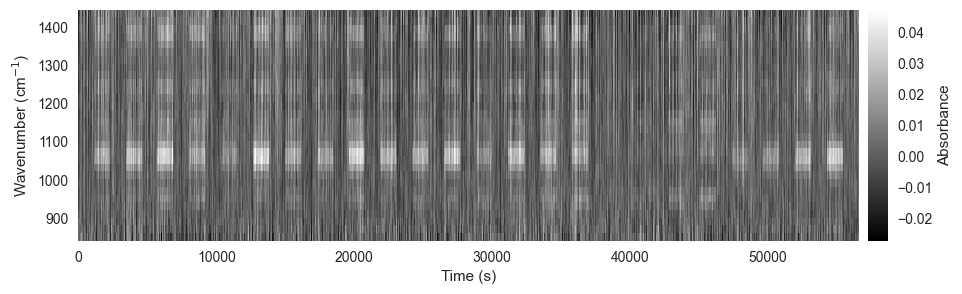

In [7]:
fig, ax = plt.subplots(figsize=(12, 3))

mesh = ax.pcolormesh(
    times,
    wavenumber,
    spectral_predictors.T,
    cmap="gray",
)

ax.set_xlabel("Time (s)")
ax.set_ylabel("Wavenumber (cm$^{-1}$)")

fig.colorbar(mesh, ax=ax, label=predictor_type.capitalize(), aspect=12, pad=0.01)

### Load calibrated concentrations

In [8]:
concentrations = []
for ii, gas in enumerate(gases):
    with open(
        Path("models", f"estimator-{gas.lower()}-{configuration}.pkl"), "rb"
    ) as file:
        calibration = pickle.load(file)

    concentration_estimator = calibration["estimator"]

    if calibration_type == "flowrate":
        concentration = concentration_estimator(flowrates[:, ii + 1])
    elif calibration_type == "pid":
        scaling_pid_to_cell = scaling_from_pid_to_cell(flowrates, split_ratio, ii + 1)
        concentration = scaling_pid_to_cell * concentration_estimator(voltages[:, ii])

    concentrations.append(concentration)

concentrations = np.stack(concentrations, axis=1)

### Load regression model

In [9]:
with open(Path("models", f"ridge-{gas_pair}-{configuration}.pkl"), "rb") as file:
    model = pickle.load(file)

concentrations_predicted = model.predict(spectral_predictors)

c:\Users\eherkert\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:380: InconsistentVersionWarning: Trying to unpickle estimator FunctionTransformer from version 1.9.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\eherkert\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:380: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\eherkert\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:380: InconsistentVersionWarning: Trying to un

### Configure Kalman filter

In [ ]:
kalman_filter = KalmanFilter(dim_x=number_gases, dim_z=number_gases)

# initial state (ppm)
kalman_filter.x = np.zeros(number_gases)

# state transition matrix: x_k = F @ x_{k-1} + w_k
kalman_filter.F = np.eye(number_gases)

# measurement matrix: z_k = H @ x_k + v_k
kalman_filter.H = np.eye(number_gases)

# gain of the equivalent exponential moving average, set by the 10-90% rise time
time_per_spectrum = np.mean(np.diff(times))
filter_time_constant = rise_time / np.log(9.0)
filter_gain = 1 - np.exp(-time_per_spectrum / filter_time_constant)

# measurement noise covariance: v_k ~ N(0, R)
kalman_filter.R = np.cov(concentrations_predicted[are_analyte_free, :].T)

# process noise covariance: w_k ~ N(0, Q)
kalman_filter.Q = kalman_filter.R * filter_gain**2 / (1 - filter_gain)

# state covariance (initial uncertainty)
kalman_filter.P = kalman_filter.R * filter_gain

print(f"Time per spectrum: {time_per_spectrum:.1f} s")
print(
    f"Filter gain: {filter_gain:.2f} "
    f"({(2 - filter_gain) / filter_gain:.1f} effectively averaged spectra)"
)
for ii, gas in enumerate(gases):
    print(
        f"{gas.capitalize()}: "
        f"measurement noise = {np.sqrt(kalman_filter.R[ii, ii]):.1f} ppm"
    )

1.2104554745106042
Time per spectrum: 64.2 s
Filter gain: 0.90 (1.2 effectively averaged spectra)
Isopropanol: measurement noise = 163.5 ppm
Ethanol: measurement noise = 128.4 ppm


In [11]:
path = Path("models", f"kalman-{gas_pair}-{configuration}.pkl")

with open(path, "wb") as file:
    pickle.dump(kalman_filter, file)

print(f"Saved: {path}")

Saved: models\kalman-isopropanol-ethanol-t1.pkl


### Inspect Kalman filter

In [12]:
concentrations_filtered = np.zeros_like(concentrations_predicted)
concentration_uncertainties = np.zeros_like(concentrations_predicted)

for ii in range(number_spectra):
    kalman_filter.predict()
    kalman_filter.update(concentrations_predicted[ii, :])

    concentrations_filtered[ii, :] = kalman_filter.x
    concentration_uncertainties[ii, :] = np.sqrt(np.diag(kalman_filter.P))

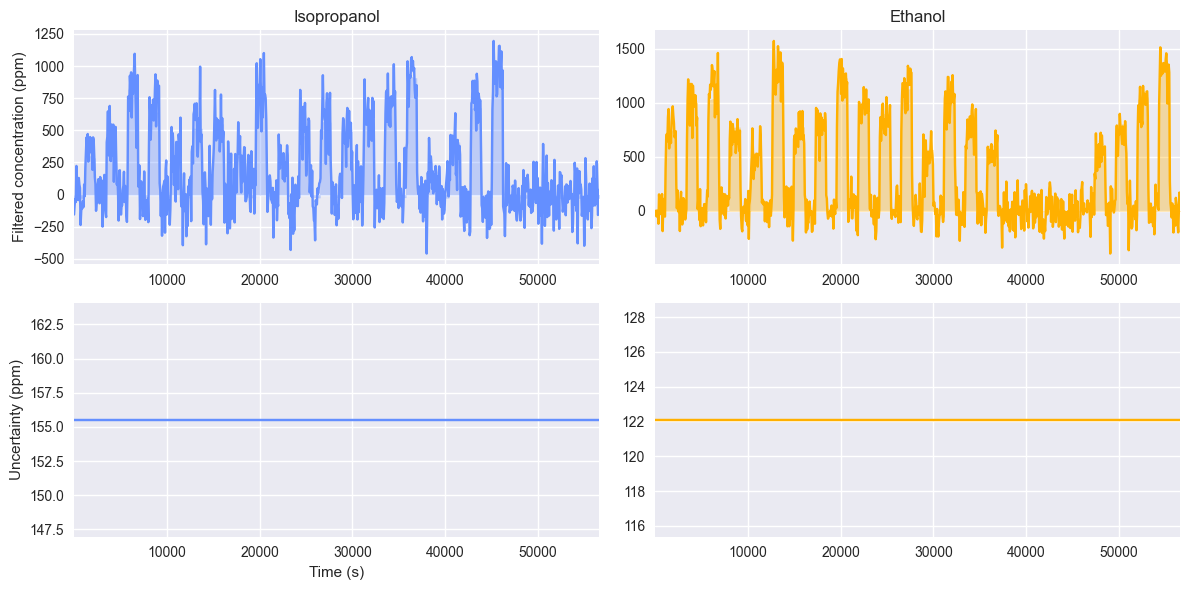

In [13]:
fig, axs = plt.subplots(
    2,
    number_gases,
    figsize=(6 * number_gases, 6),
    squeeze=False,
)

for ii, gas in enumerate(gases):
    axs[0, ii].plot(
        times,
        concentrations_filtered[:, ii],
        color=colors[ii],
        zorder=10,
    )
    axs[0, ii].fill_between(
        times,
        concentrations[:, ii],
        color=colors[ii] + "55",
        zorder=5,
    )

    axs[1, ii].plot(
        times,
        concentration_uncertainties[:, ii],
        color=colors[ii],
        zorder=10,
    )

    axs[0, ii].margins(x=0)
    axs[1, ii].margins(x=0)

    axs[0, ii].set_title(gas.capitalize())

axs[-1, 0].set_xlabel("Time (s)")
axs[0, 0].set_ylabel("Filtered concentration (ppm)")
axs[-1, 0].set_ylabel("Uncertainty (ppm)")

fig.tight_layout()